<a href="https://colab.research.google.com/github/Mobina2003/Analysis-of-stock-market-data/blob/main/project_webmelat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Load Data and Initial Exploration

First, we'll load the `webmelat.csv` file into a pandas DataFrame. Then, we'll display the first few rows, check the data types, and get a summary of the dataset to understand its basic structure.

In [ ]:
!pip install pmdarima --quiet

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import numpy as np
import pmdarima as pm
import scipy.stats as stats



df = pd.read_csv('/content/webmelat.csv')

display(df.head())

,Unnamed: 0,date,open,high,low,adjClose,value,volume,count,yesterday,close
0,0,2009-02-18,1050.0,1050.0,1050.0,1050.0,347393807250,330851245,800,1000.0,1050.0
1,1,2009-02-21,1051.0,1076.0,1042.0,1050.0,352194689892,335334212,6457,1050.0,1057.0
2,2,2009-02-22,1065.0,1074.0,1055.0,1065.0,8981292784,8435464,603,1050.0,1055.0
3,3,2009-02-23,1066.0,1067.0,1059.0,1061.0,9090532333,8570222,937,1065.0,1060.0
4,4,2009-02-25,1061.0,1064.0,1050.0,1058.0,7863032258,7434309,616,1061.0,1060.0


In [ ]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3608 entries, 0 to 3607
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  3608 non-null   int64  
 1   date        3608 non-null   object 
 2   open        3608 non-null   float64
 3   high        3608 non-null   float64
 4   low         3608 non-null   float64
 5   adjClose    3608 non-null   float64
 6   value       3608 non-null   int64  
 7   volume      3608 non-null   int64  
 8   count       3608 non-null   int64  
 9   yesterday   3608 non-null   float64
 10  close       3608 non-null   float64
dtypes: float64(6), int64(4), object(1)
memory usage: 310.2+ KB


None

In [ ]:
display(df.describe())

,Unnamed: 0,open,high,low,adjClose,value,volume,count,yesterday,close
count,3608.000000,3608.000000,3608.000000,3608.000000,3608.000000,3.608000e+03,3.608000e+03,3608.000000,3608.000000,3608.000000
mean,1803.500000,2749.939302,2796.733647,2701.002772,2750.344512,7.178080e+11,2.737006e+08,5388.026330,2741.836475,2745.137472
std,1041.684213,2756.429420,2837.742510,2683.751409,2761.391752,1.639141e+12,8.133545e+08,9866.587477,2732.977997,2755.251698
min,0.000000,900.000000,907.000000,880.000000,897.000000,3.476044e+06,2.678000e+03,1.000000,869.000000,900.000000
25%,901.750000,1407.250000,1433.500000,1391.500000,1418.000000,8.650673e+09,5.889729e+06,353.750000,1406.500000,1412.500000
50%,1803.500000,2201.000000,2230.000000,2172.000000,2203.500000,6.886787e+10,3.178192e+07,1614.000000,2199.000000,2200.000000
75%,2705.250000,2998.000000,3031.000000,2930.500000,2990.000000,6.160993e+11,1.764296e+08,6084.250000,2975.000000,2970.250000
max,3607.000000,27350.000000,28330.000000,26500.000000,27160.000000,1.927171e+13,1.388074e+10,120381.000000,26990.000000,27330.000000


### 2. Data Preprocessing and Visualization

> Add blockquote



We'll convert the 'date' column to datetime objects and set it as the index. Then, we'll select the 'close' price as our primary time series for analysis and visualize it to observe any trends or patterns.

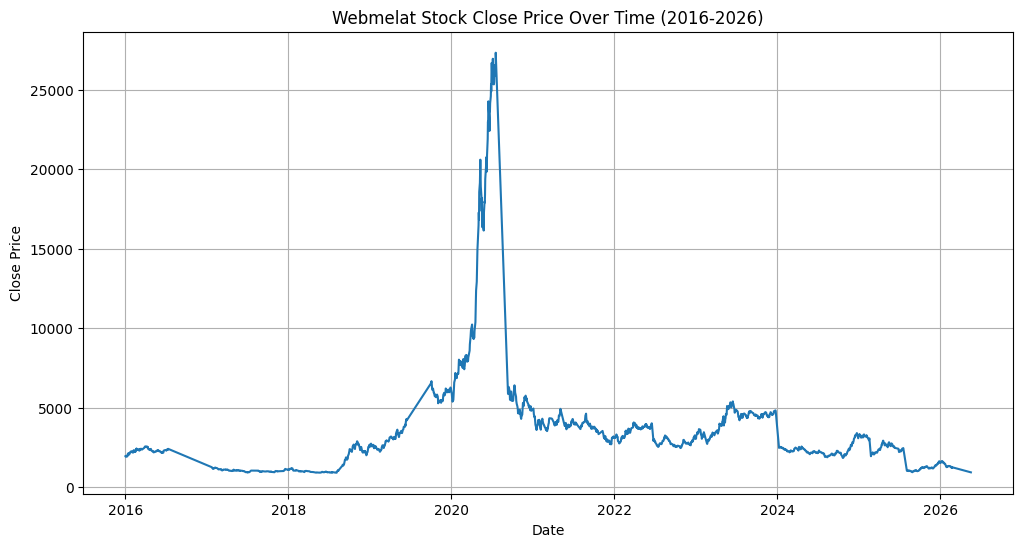

,close
date,
2016-01-02,1938.0
2016-01-03,1914.0
2016-01-04,1904.0
2016-01-05,1921.0
2016-01-06,1967.0


In [ ]:

# Convert 'date' column to datetime and set as index
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)

# Filter data for the years 2016 to 2026
df_filtered = df[(df.index.year >= 2016) & (df.index.year <= 2026)]

ts = df_filtered['close']

plt.figure(figsize=(12, 6))
plt.plot(ts)
plt.title('Webmelat Stock Close Price Over Time (2016-2026)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.grid(True)
plt.show()

display(ts.head())

### 3. Check for Trend and Seasonality

Before delving into stationarity tests and ACF/PACF plots, it's beneficial to visually inspect the time series for overall trends and repeating seasonal patterns. We'll use `seasonal_decompose` from `statsmodels` to break down the time series into its constituent components: trend, seasonality, and residuals.

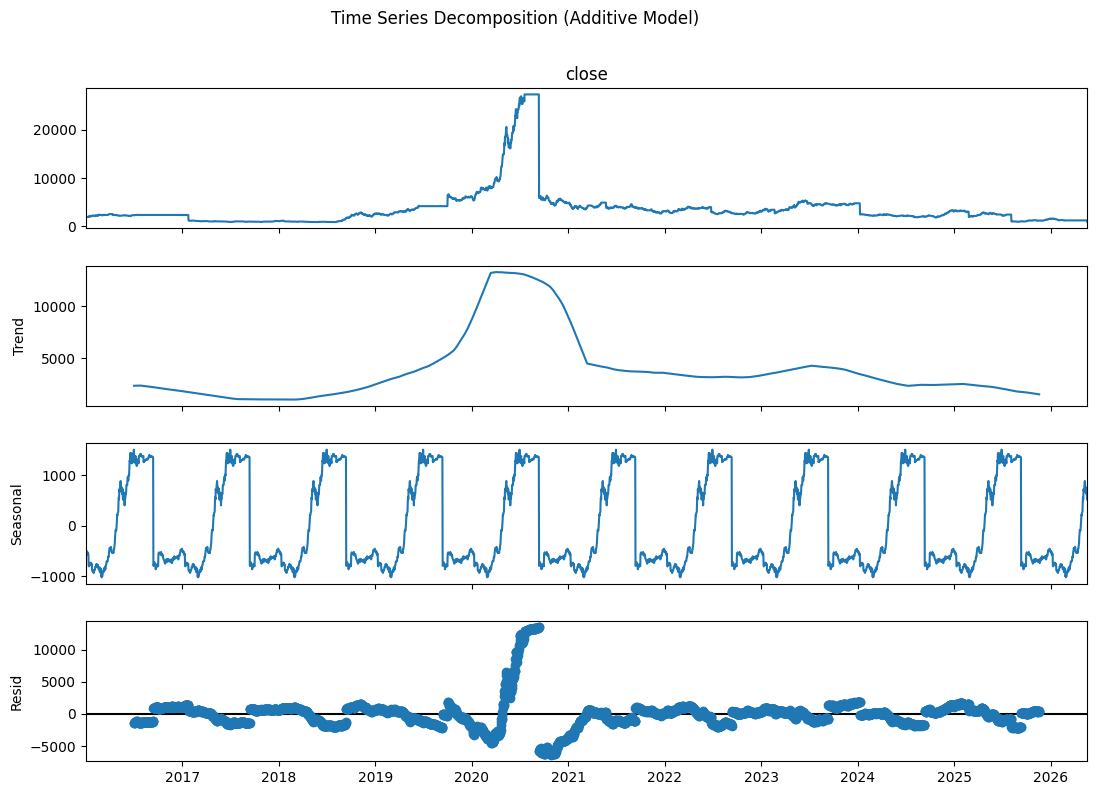

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# To avoid issues with missing frequencies, let's resample the data to daily frequency and fill missing values.
# This makes seasonal_decompose more robust if the original data has irregular gaps.
daily_ts = ts.asfreq('D')
daily_ts = daily_ts.ffill() # Forward fill missing values (updated to suppress FutureWarning)

# Try to decompose with an additive model first.
# If the seasonal component is multiplicative (amplitude changes with level), try model='multiplicative'.
try:
    decomposition = seasonal_decompose(daily_ts, model='additive', period=365)
    fig = decomposition.plot()
    fig.set_size_inches(12, 8)
    plt.suptitle('Time Series Decomposition (Additive Model)', y=1.02)
    plt.show()
except ValueError as e:
    print(f"Could not perform additive decomposition, trying multiplicative: {e}")
    try:
        decomposition = seasonal_decompose(daily_ts, model='multiplicative', period=365)
        fig = decomposition.plot()
        fig.set_size_inches(12, 8)
        plt.suptitle('Time Series Decomposition (Multiplicative Model)', y=1.02)
        plt.show()
    except Exception as e:
        print(f"Could not perform multiplicative decomposition either: {e}")
        print("Seasonal decomposition requires a minimum number of observations per period.")
        print("Please ensure your data has sufficient length for the chosen period.")

### 4. Stationarity Check and ACF/PACF Plots

We'll perform the Augmented Dickey-Fuller (ADF) test to check for stationarity. Non-stationary time series often require differencing. Additionally, we'll plot the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) to help determine the `p` and `q` orders for the ARMA/ARIMA models.

In [ ]:
def adf_test(series):
    result = adfuller(series, autolag='AIC')
    print(f'ADF Statistic: {result[0]:.2f}')
    print(f'p-value: {result[1]:.2f}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'   {key}: {value:.2f}')
    if result[1] <= 0.05:
        print("Reject the null hypothesis (Ho), the series is stationary")
    else:
        print("Fail to reject the null hypothesis (Ho), the series is not stationary")

print('ADF Test Results for Close Price:')
adf_test(ts)


ADF Test Results for Close Price:
ADF Statistic: -3.50
p-value: 0.01
Critical Values:
   1%: -3.43
   5%: -2.86
   10%: -2.57
Reject the null hypothesis (Ho), the series is stationary


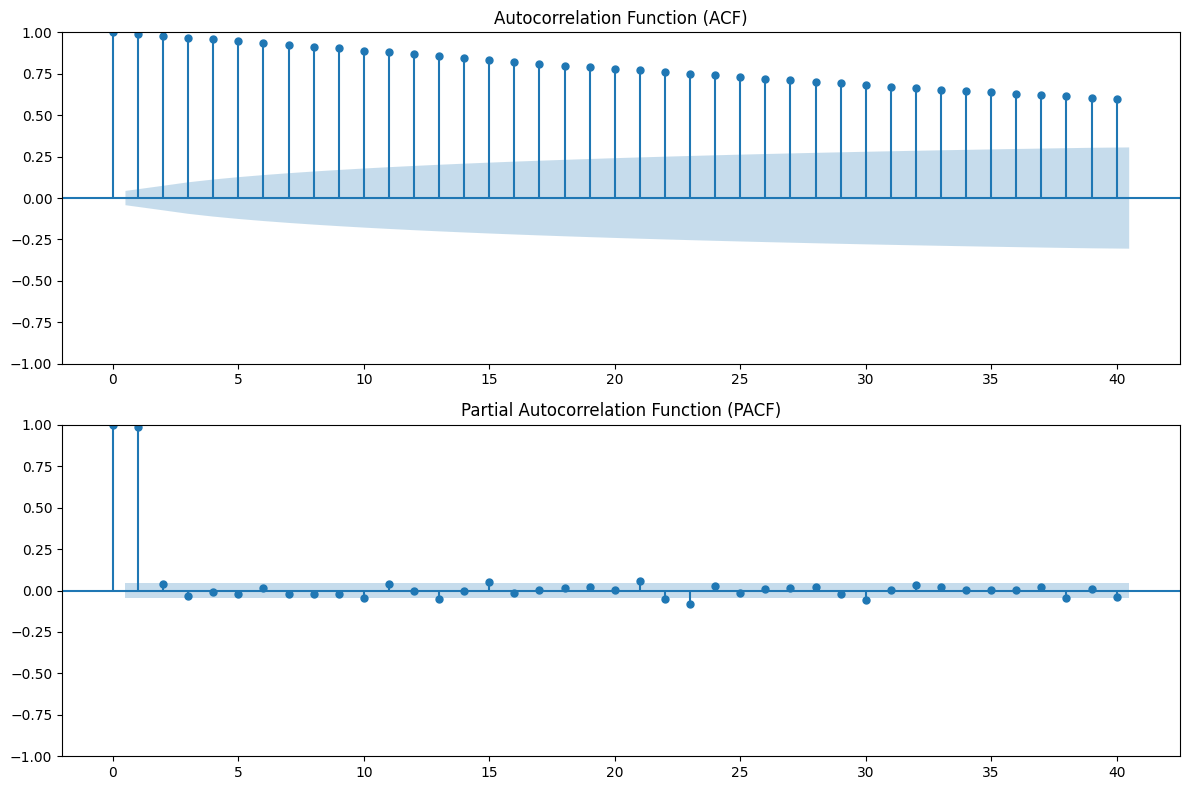

In [ ]:
# Plot ACF and PACF
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(ts, ax=axes[0], lags=40)
axes[0].set_title('Autocorrelation Function (ACF)')
plot_pacf(ts, ax=axes[1], lags=40, method='ywm')
axes[1].set_title('Partial Autocorrelation Function (PACF)')
plt.tight_layout()
plt.show()

### 5. Differencing

If the time series is found to be non-stationary after the ADF test, we'll apply differencing to make it stationary. This step is crucial for ARIMA modeling. We'll typically start with first-order differencing and re-evaluate stationarity.

ADF Test Results for Differenced Close Price:
ADF Statistic: -9.64
p-value: 0.00
Critical Values:
   1%: -3.43
   5%: -2.86
   10%: -2.57
Reject the null hypothesis (Ho), the series is stationary


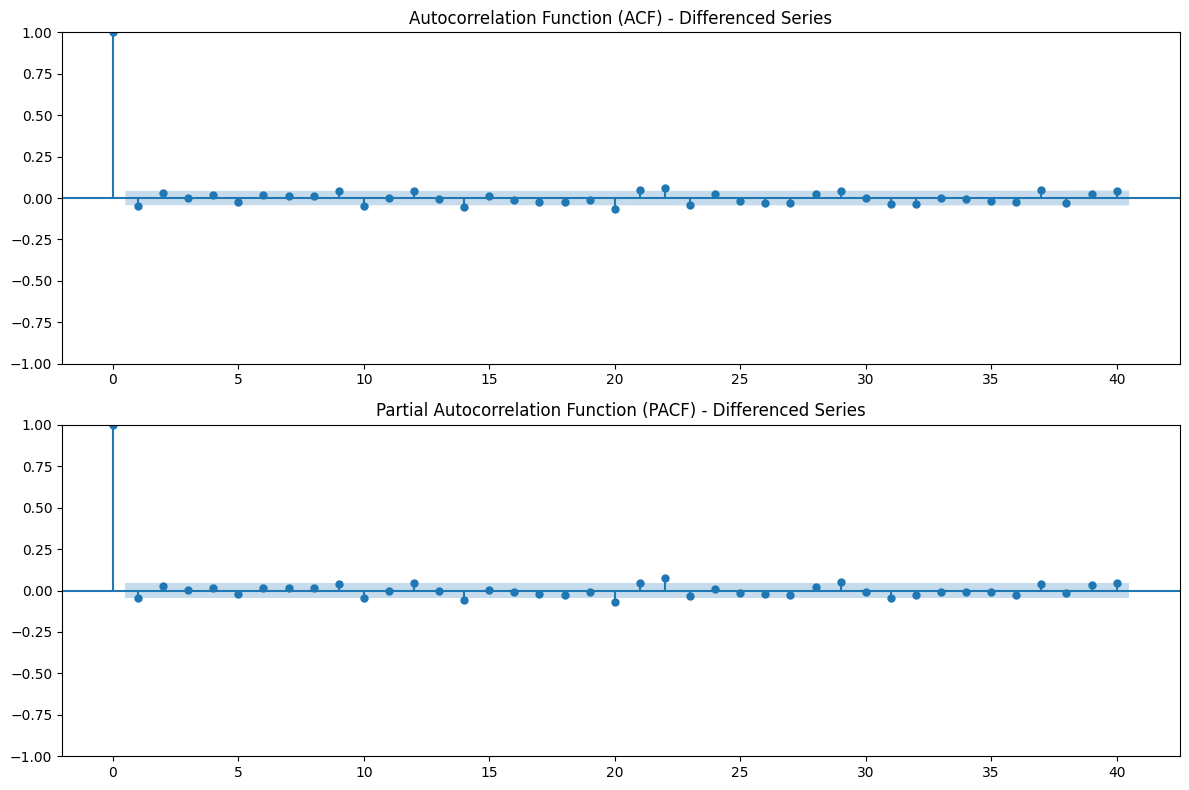

In [ ]:
# Apply first-order differencing
ts_diff = ts.diff().dropna()

print('ADF Test Results for Differenced Close Price:')
adf_test(ts_diff)

# Plot ACF and PACF for differenced series
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(ts_diff, ax=axes[0], lags=40)
axes[0].set_title('Autocorrelation Function (ACF) - Differenced Series')
plot_pacf(ts_diff, ax=axes[1], lags=40, method='ywm')
axes[1].set_title('Partial Autocorrelation Function (PACF) - Differenced Series')
plt.tight_layout()
plt.show()

### 5.1 Log Transformation and Stationarity Check

To further stabilize the variance and potentially improve stationarity, we will apply a natural logarithm transformation to the 'close' price series. After transformation, we will re-run the ADF test and plot ACF/PACF to determine the appropriate differencing order and AR/MA terms for the log-transformed series.

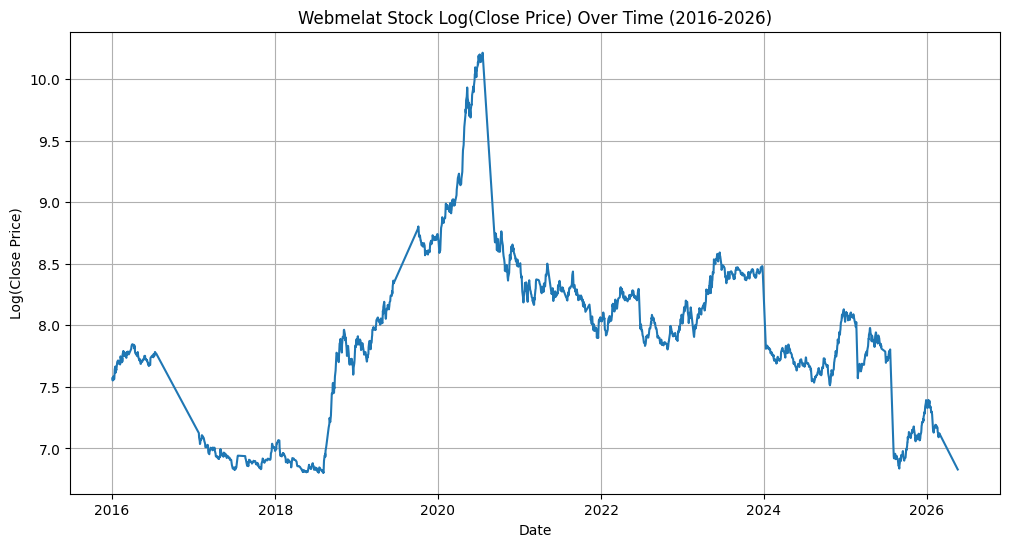

,close
date,
2016-01-02,7.569412
2016-01-03,7.556951
2016-01-04,7.551712
2016-01-05,7.560601
2016-01-06,7.584265


In [ ]:
# Apply natural logarithm transformation
ts_log = np.log(ts)

plt.figure(figsize=(12, 6))
plt.plot(ts_log)
plt.title('Webmelat Stock Log(Close Price) Over Time (2016-2026)')
plt.xlabel('Date')
plt.ylabel('Log(Close Price)')
plt.grid(True)
plt.show()

display(ts_log.head())

ADF Test Results for Log-Transformed Close Price:
ADF Statistic: -1.51
p-value: 0.53
Critical Values:
   1%: -3.43
   5%: -2.86
   10%: -2.57
Fail to reject the null hypothesis (Ho), the series is not stationary


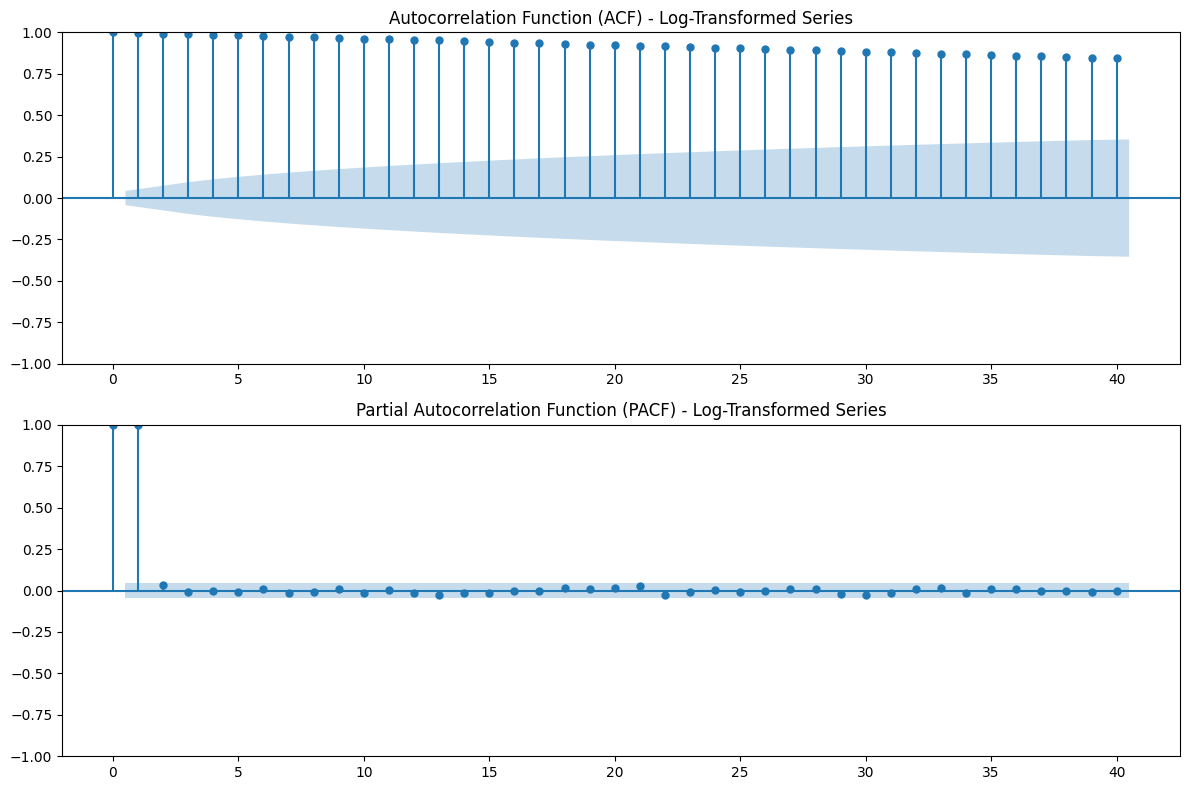

In [ ]:
print('ADF Test Results for Log-Transformed Close Price:')
adf_test(ts_log)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(ts_log, ax=axes[0], lags=40)
axes[0].set_title('Autocorrelation Function (ACF) - Log-Transformed Series')
plot_pacf(ts_log, ax=axes[1], lags=40, method='ywm')
axes[1].set_title('Partial Autocorrelation Function (PACF) - Log-Transformed Series')
plt.tight_layout()
plt.show()

### 5.2 Differencing on Log-Transformed Series

If the log-transformed series is still non-stationary, we will apply first-order differencing to it and re-evaluate stationarity. This will result in a series representing the log returns, a common practice in financial time series analysis.

ADF Test Results for Differenced Log-Transformed Close Price (Log Returns):
ADF Statistic: -44.73
p-value: 0.00
Critical Values:
   1%: -3.43
   5%: -2.86
   10%: -2.57
Reject the null hypothesis (Ho), the series is stationary


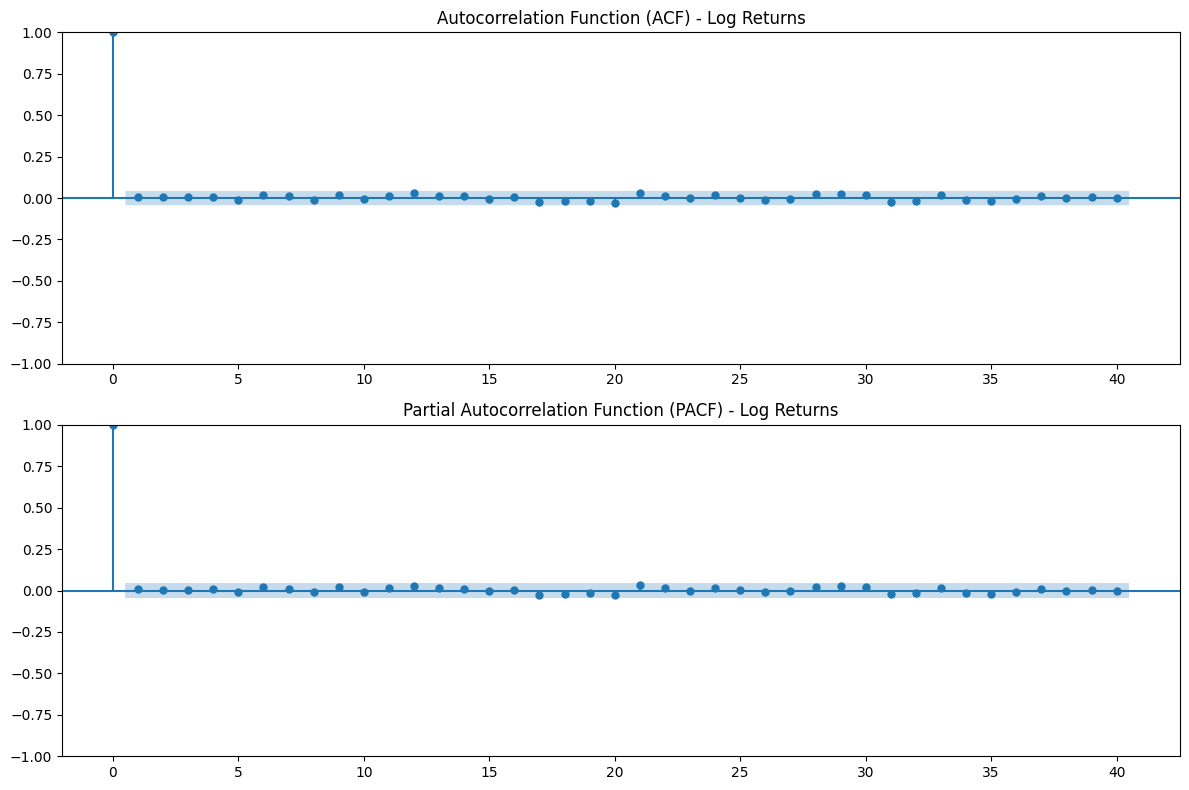

In [ ]:
# Apply first-order differencing to the log-transformed series
ts_log_diff = ts_log.diff().dropna()

print('ADF Test Results for Differenced Log-Transformed Close Price (Log Returns):')
adf_test(ts_log_diff)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(ts_log_diff, ax=axes[0], lags=40)
axes[0].set_title('Autocorrelation Function (ACF) - Log Returns')
plot_pacf(ts_log_diff, ax=axes[1], lags=40, method='ywm')
axes[1].set_title('Partial Autocorrelation Function (PACF) - Log Returns')
plt.tight_layout()
plt.show()

### 5.3 ARIMA Model on Log-Transformed and Differenced Series (Log Returns)

Now that we have a stationary series (`ts_log_diff`), we will apply an ARIMA model to it. We will use `auto_arima` to find the optimal `p`, `d`, and `q` orders for the log-differenced series. Note that for this series, `d` will be 0 internally to `auto_arima` because we have already differenced it once. The `p` and `q` values will be determined by the `auto_arima` function.

In [ ]:
# Split the log-differenced data into training and testing sets
train_log_diff_size = int(len(ts_log_diff) * 0.8)
train_log_diff, test_log_diff = ts_log_diff[0:train_log_diff_size], ts_log_diff[train_log_diff_size:len(ts_log_diff)]

print(f"Training set size (log-diff): {len(train_log_diff)}")
print(f"Testing set size (log-diff): {len(test_log_diff)}")


Training set size (log-diff): 1656
Testing set size (log-diff): 415


In [ ]:
# Find the best ARIMA model using auto_arima on the log-differenced series
# For ts_log_diff, d should be 0 because the series is already differenced.
# auto_arima will find the p and q orders for this already-differenced series.

print("Searching for the best ARIMA model order for log-differenced series...")
auto_model_log_diff = pm.auto_arima(train_log_diff, start_p=1, start_q=1,
                                   test='adf',       # Use ADF test to confirm 'd' (should be 0 here)
                                   max_p=5, max_q=5, # Maximum p and q
                                   m=1,              # Frequency of the series (1 for non-seasonal)
                                   d=0,           # Set d=0 as series is already differenced to stationarity
                                   seasonal=False,   # No seasonal component for now
                                   trace=True,
                                   error_action='ignore',
                                   suppress_warnings=True,
                                   stepwise=True)

print("\nBest ARIMA Model Order for Log-Differenced Series:", auto_model_log_diff.order)
print(auto_model_log_diff.summary())


Searching for the best ARIMA model order for log-differenced series...
Performing stepwise search to minimize aic
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=-5004.467, Time=0.38 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=-5007.926, Time=0.13 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=-5006.090, Time=0.10 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=-5006.086, Time=0.21 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=-5005.938, Time=0.29 sec

Best model:  ARIMA(0,0,0)(0,0,0)[0]          
Total fit time: 1.111 seconds

Best ARIMA Model Order for Log-Differenced Series: (0, 0, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1656
Model:                        SARIMAX   Log Likelihood                2504.963
Date:                Wed, 17 Jun 2026   AIC                          -5007.926
Time:                        18:31:20   BIC                          -5002.514
Sample:          

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)



ARIMA Model Summary for Log Returns:
                               SARIMAX Results                                
Dep. Variable:                  close   No. Observations:                 1656
Model:                          ARIMA   Log Likelihood                2504.969
Date:                Wed, 17 Jun 2026   AIC                          -5005.938
Time:                        18:31:21   BIC                          -4995.114
Sample:                             0   HQIC                         -5001.926
                               - 1656                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0001      0.002      0.066      0.948      -0.004       0.004
sigma2         0.0028   1.06e-05    268.590      0.000       0.003       0.003
Ljung-Box (L1)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
/tmp/ipykernel_10169/1273009913.py:18: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  last_log_value = ts_log[len(train_log_diff)-1] # This is ts_log, not ts_log_diff


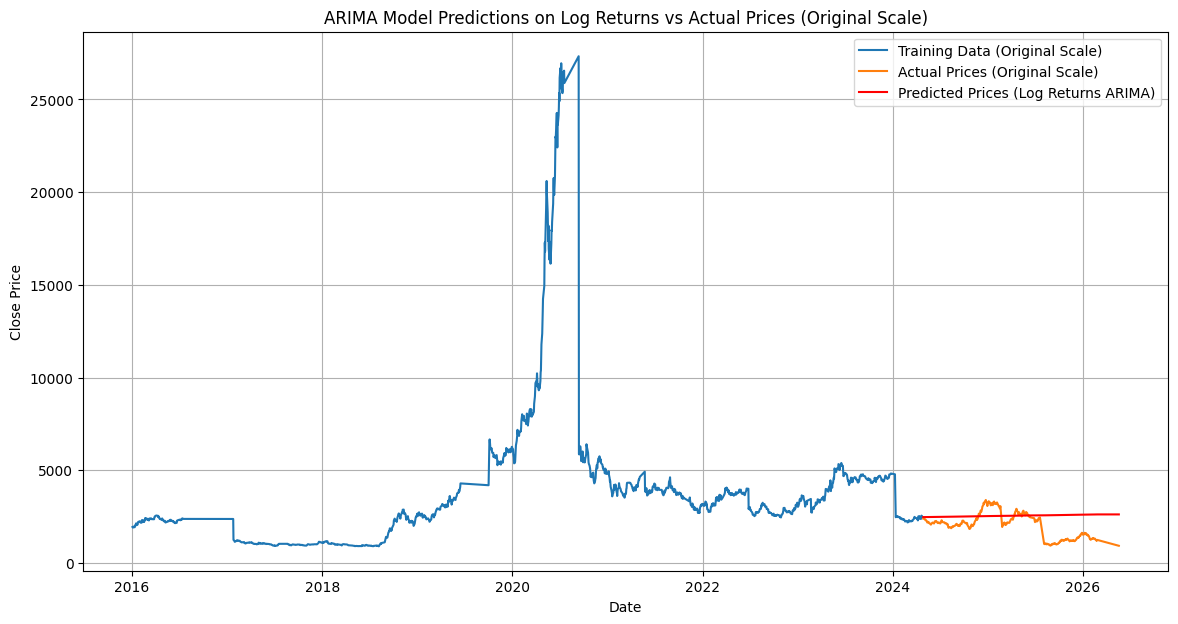

In [ ]:
# Fit the ARIMA model with the parameters found by auto_arima on the log-differenced series
best_order_log_diff = auto_model_log_diff.order

# The order parameter for ARIMA takes (p, d, q). Since train_log_diff is already differenced, d should be 0.
# The best_order_log_diff from auto_arima will already reflect this (p,0,q).
model_log_diff = ARIMA(train_log_diff, order=best_order_log_diff)
model_log_diff_fit = model_log_diff.fit()

print("\nARIMA Model Summary for Log Returns:")
print(model_log_diff_fit.summary())

# Make predictions on the log-differenced test set
start_log_diff = len(train_log_diff)
end_log_diff = len(train_log_diff) + len(test_log_diff) - 1
predictions_log_diff = model_log_diff_fit.predict(start=start_log_diff, end=end_log_diff)

# Get the last value of the *log-transformed* training series for undifferencing
last_log_value = ts_log[len(train_log_diff)-1] # This is ts_log, not ts_log_diff

# Reconstruct the log series from predictions and the last known log value
predicted_log_values = last_log_value + predictions_log_diff.cumsum()

# Exponentiate to get predicted prices and assign the correct date index
predicted_prices_log_diff = pd.Series(np.exp(predicted_log_values.values), index=test_log_diff.index)

# Create a Series for the actual prices corresponding to the test_log_diff index
# We need the original 'ts' values corresponding to the test set dates for comparison.
actual_prices_for_comparison = ts[test_log_diff.index]

# Plot predictions vs actuals
plt.figure(figsize=(14, 7))
plt.plot(ts_log_diff.index[:len(train_log_diff)], np.exp(ts_log[:len(train_log_diff)]), label='Training Data (Original Scale)') # Plot original scale training for context
plt.plot(actual_prices_for_comparison.index, actual_prices_for_comparison, label='Actual Prices (Original Scale)')
plt.plot(predicted_prices_log_diff.index, predicted_prices_log_diff, color='red', label='Predicted Prices (Log Returns ARIMA)')
plt.title('ARIMA Model Predictions on Log Returns vs Actual Prices (Original Scale)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

### 6. ARIMA Model Fitting

Based on the ACF and PACF plots (of the original or differenced series) and the stationarity test, we'll determine the appropriate `p`, `d`, and `q` orders for our ARIMA model. We'll then split the data into training and testing sets, fit the model, and make predictions.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/p

                               SARIMAX Results                                
Dep. Variable:                  close   No. Observations:                 1657
Model:                 ARIMA(5, 1, 0)   Log Likelihood              -12845.876
Date:                Wed, 17 Jun 2026   AIC                          25703.752
Time:                        18:31:21   BIC                          25736.225
Sample:                             0   HQIC                         25715.789
                               - 1657                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0460      0.014     -3.335      0.001      -0.073      -0.019
ar.L2          0.0263      0.018      1.448      0.148      -0.009       0.062
ar.L3          0.0050      0.037      0.134      0.8

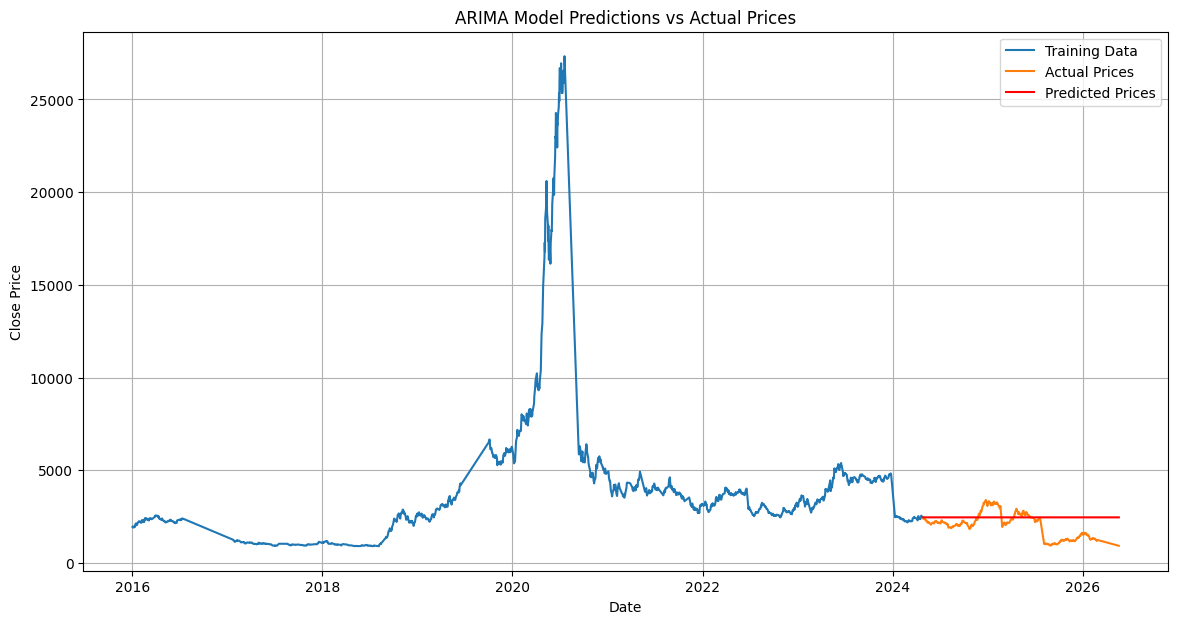

In [ ]:
# Split data into training and testing sets
train_size = int(len(ts) * 0.8)
train, test = ts[0:train_size], ts[train_size:len(ts)]

# Define the ARIMA model parameters (p,d,q).
p_order = 5 # Example: AR order
d_order = 1 # Example: I order (differencing order)
q_order = 0 # Example: MA order

# Fit ARIMA model
# Using the non-differenced series and letting ARIMA handle the differencing if d > 0
model = ARIMA(train, order=(p_order, d_order, q_order))
model_fit = model.fit()

# Print model summary
print(model_fit.summary())

# Make predictions
start = len(train)
end = len(train) + len(test) - 1
predictions = model_fit.predict(start=start, end=end, dynamic=False)

# Plot predictions vs actuals
plt.figure(figsize=(14, 7))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Actual Prices')
plt.plot(test.index, predictions, color='red', label='Predicted Prices')
plt.title('ARIMA Model Predictions vs Actual Prices')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

### 7. Model Evaluation

We'll evaluate the performance of our ARIMA model using metrics like Mean Squared Error (MSE) or Root Mean Squared Error (RMSE). This will help us understand how well the model predicts future values.

In [ ]:
rmse = np.sqrt(mean_squared_error(test, predictions))
print(f'Test RMSE: {rmse:.3f}')

Test RMSE: 795.164


### 8. Fitting an ARMA Model (ARIMA with d=0)

Given that the original series was found to be stationary by the ADF test, an ARMA model might be more appropriate than an ARIMA model with differencing (`d > 0`). We will fit an ARMA model (i.e., ARIMA with `d=0`) and compare its performance.


ARMA Model Summary:
                               SARIMAX Results                                
Dep. Variable:                  close   No. Observations:                 1657
Model:                 ARIMA(1, 0, 0)   Log Likelihood              -12853.450
Date:                Wed, 17 Jun 2026   AIC                          25712.900
Time:                        18:31:21   BIC                          25729.138
Sample:                             0   HQIC                         25718.919
                               - 1657                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       3787.4815   4273.422      0.886      0.375   -4588.271    1.22e+04
ar.L1          0.9882      0.004    252.629      0.000       0.981       0.996
sigma2      3.195e+05   1930.73

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/p

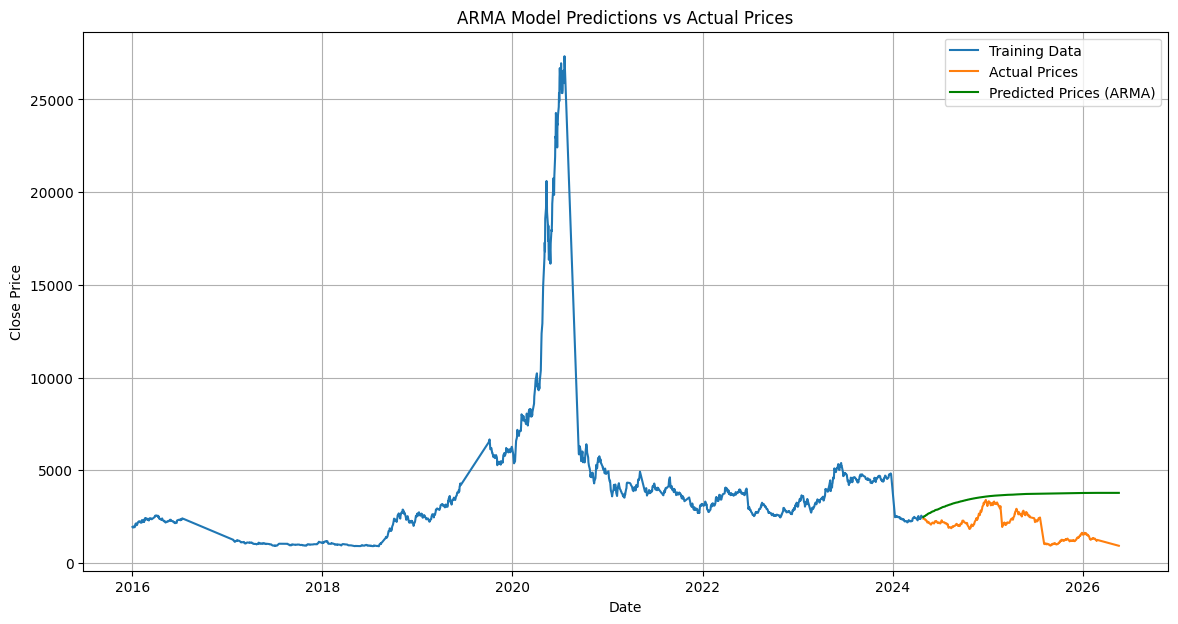

In [ ]:
# Define the ARMA model parameters (p, 0, q).
p_arma = 1 # Example: AR order
d_arma = 0 # No differencing for ARMA
q_arma = 0 # Example: MA order (could be 1 if ACF showed a clear cutoff)

# Fit ARMA model (using original, non-differenced training data)
model_arma = ARIMA(train, order=(p_arma, d_arma, q_arma))
model_arma_fit = model_arma.fit()

# Print model summary
print("\nARMA Model Summary:")
print(model_arma_fit.summary())

# Make predictions
predictions_arma = model_arma_fit.predict(start=start, end=end, dynamic=False)

# Plot predictions vs actuals
plt.figure(figsize=(14, 7))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Actual Prices')
plt.plot(test.index, predictions_arma, color='green', label='Predicted Prices (ARMA)')
plt.title('ARMA Model Predictions vs Actual Prices')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

### 9. Evaluating the ARMA Model

We'll evaluate the performance of our ARMA model using RMSE and compare it with the ARIMA model's performance.

In [ ]:
rmse_arma = np.sqrt(mean_squared_error(test, predictions_arma))
print(f'ARMA Test RMSE: {rmse_arma:.3f}')
print(f'Previous ARIMA Test RMSE: {rmse:.3f}')

if rmse_arma < rmse:
    print("The ARMA model performed better (lower RMSE) than the ARIMA model.")
else:
    print("The ARIMA model performed better (lower RMSE) than the ARMA model.")

ARMA Test RMSE: 1701.348
Previous ARIMA Test RMSE: 795.164
The ARIMA model performed better (lower RMSE) than the ARMA model.


### 10. Forecast Next Year's Stock Prices

Using the better-performing ARIMA model, we'll now forecast the stock prices for the next year. We will generate future dates and use the model's `forecast` method to get the predictions.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


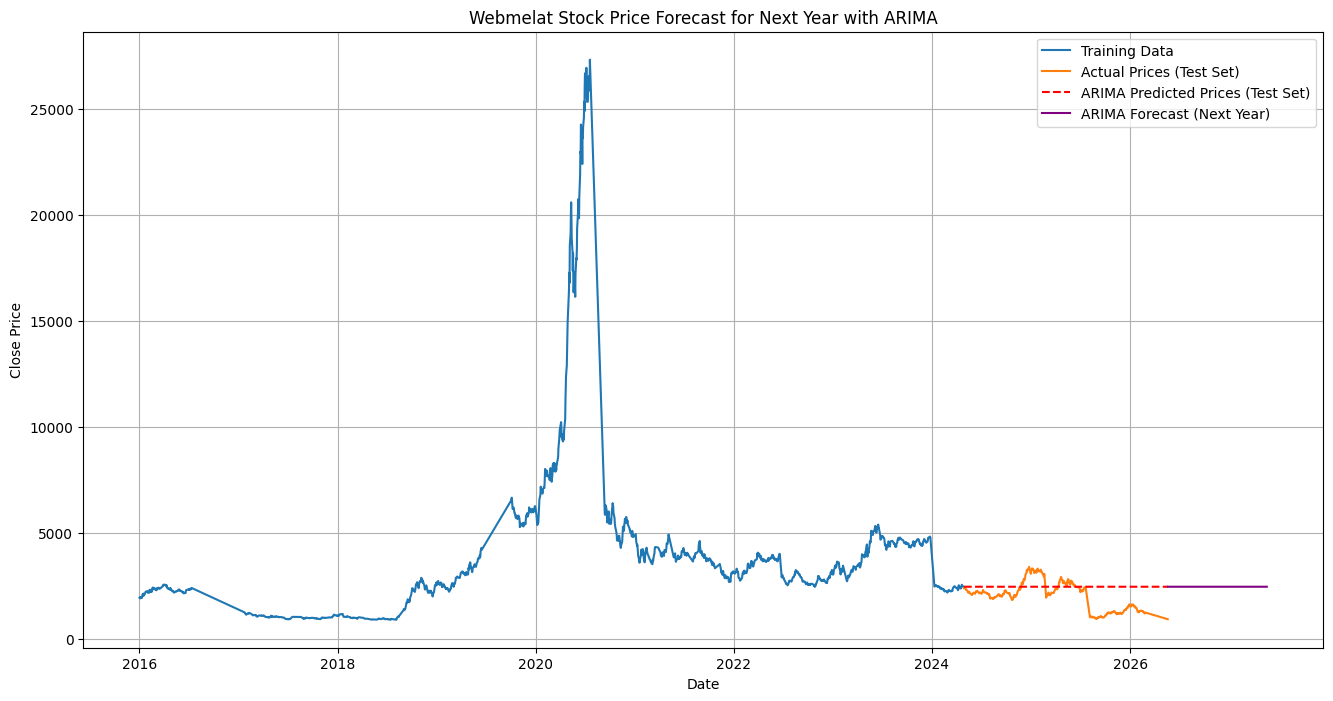

,0
2026-05-20,2457.134764
2026-05-21,2456.530926
2026-05-22,2456.373404
2026-05-23,2456.531057
2026-05-24,2456.821236


In [ ]:
# Calculate average frequency in days
freq_days = ts.index.to_series().diff().dt.days.mean()
n_forecast_steps = 365 # Forecast for approximately one year

# Forecast future values using the ARIMA model (model_fit)
forecast = model_fit.forecast(steps=n_forecast_steps)

# Generate future dates for the forecast
last_date = ts.index[-1]
forecast_dates = pd.date_range(start=last_date, periods=n_forecast_steps + 1, freq='D')
forecast_dates = forecast_dates[1:] # Exclude the last_date itself

# Create a Series for the forecast with the new dates
forecast_series = pd.Series(forecast.values, index=forecast_dates)

# Plot the historical data, test data, and the forecast
plt.figure(figsize=(16, 8))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Actual Prices (Test Set)')
plt.plot(test.index, predictions, color='red', linestyle='--', label='ARIMA Predicted Prices (Test Set)')
plt.plot(forecast_series.index, forecast_series, color='purple', label='ARIMA Forecast (Next Year)')
plt.title('Webmelat Stock Price Forecast for Next Year with ARIMA')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

display(forecast_series.head())

### 11. Refining ARIMA Model with `auto_arima`

The current ARIMA model's forecast is quite flat, indicating that the chosen parameters (p=5, d=1, q=0) might not be optimal for capturing the underlying dynamics of the stock price. To find a better model order, we will use `auto_arima` from the `pmdarima` library. This function automates the process of finding the best ARIMA parameters (p, d, q) that minimize a chosen information criterion (like AIC or BIC).

In [ ]:
# Find the best ARIMA model using auto_arima
# We'll use stepwise search to reduce computation time
# start_p, start_q: initial values for p and q
# max_p, max_q: maximum values for p and q
# d: order of differencing (can be set to None to let auto_arima determine)
# seasonal: set to False for non-seasonal ARIMA
# trace: prints status during the search
# suppress_warnings: suppresses warnings thrown by statsmodels
# stepwise: uses a stepwise algorithm to speed up parameter search
# error_action: what to do if an ARIMA model fails to fit (e.g., 'ignore', 'warn', 'raise')
# approximation: whether to use approximate or exact SARIMAX likelihood during evaluation

print("Searching for the best ARIMA model order...")
auto_model = pm.auto_arima(train, start_p=1, start_q=1,
                           test='adf',       # Use ADF test to determine 'd'
                           max_p=5, max_q=5, # Maximum p and q
                           m=1,              # Frequency of the series (1 for non-seasonal)
                           d=1,           # Let model determine 'd'
                           seasonal=False,   # No seasonal component for now
                           trace=True,
                           error_action='ignore',
                           suppress_warnings=True,
                           stepwise=True)

print("\nBest ARIMA Model Order:", auto_model.order)
print(auto_model.summary())

Searching for the best ARIMA model order...
Performing stepwise search to minimize aic
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=25700.866, Time=0.60 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=25701.846, Time=0.06 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=25700.114, Time=0.09 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=25700.314, Time=0.17 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=25699.847, Time=0.04 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 0.971 seconds

Best ARIMA Model Order: (0, 1, 0)
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1657
Model:               SARIMAX(0, 1, 0)   Log Likelihood              -12848.923
Date:                Wed, 17 Jun 2026   AIC                          25699.847
Time:                        18:31:23   BIC                          25705.259
Sample:                             0   HQIC                         25


Refined ARIMA Model Summary:
                               SARIMAX Results                                
Dep. Variable:                  close   No. Observations:                 1657
Model:                 ARIMA(0, 1, 0)   Log Likelihood              -12848.923
Date:                Wed, 17 Jun 2026   AIC                          25699.847
Time:                        18:31:23   BIC                          25705.259
Sample:                             0   HQIC                         25701.853
                               - 1657                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      3.211e+05    448.272    716.330      0.000     3.2e+05    3.22e+05
Ljung-Box (L1) (Q):                   3.73   Jarque-Bera (JB):         105708777.09
Prob(Q):         

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/p

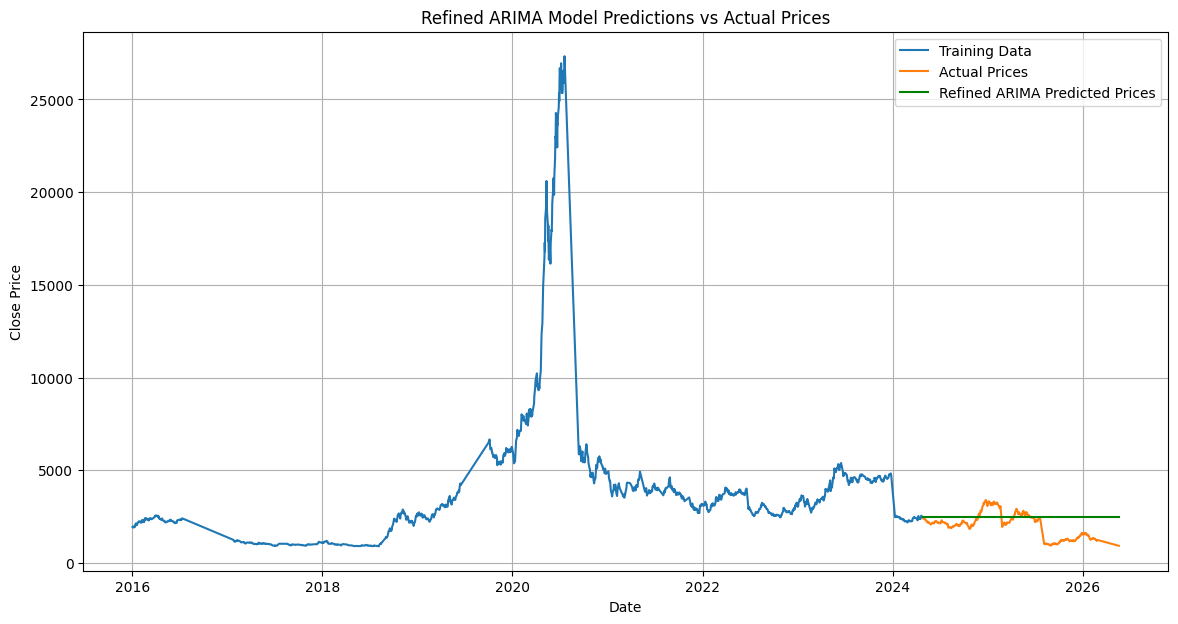

In [ ]:
# Fit the ARIMA model with the parameters found by auto_arima
# Extract the best order (p, d, q)
best_order = auto_model.order

model_refined = ARIMA(train, order=best_order)
model_refined_fit = model_refined.fit()

print("\nRefined ARIMA Model Summary:")
print(model_refined_fit.summary())

# Make predictions with the refined model
predictions_refined = model_refined_fit.predict(start=start, end=end, dynamic=False)

# Plot predictions vs actuals with refined model
plt.figure(figsize=(14, 7))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Actual Prices')
plt.plot(test.index, predictions_refined, color='green', label='Refined ARIMA Predicted Prices')
plt.title('Refined ARIMA Model Predictions vs Actual Prices')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

### 12. Forecast Next Year's Stock Prices with Refined ARIMA Model

Now, let's use the refined ARIMA model to forecast the stock prices for the next year.

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


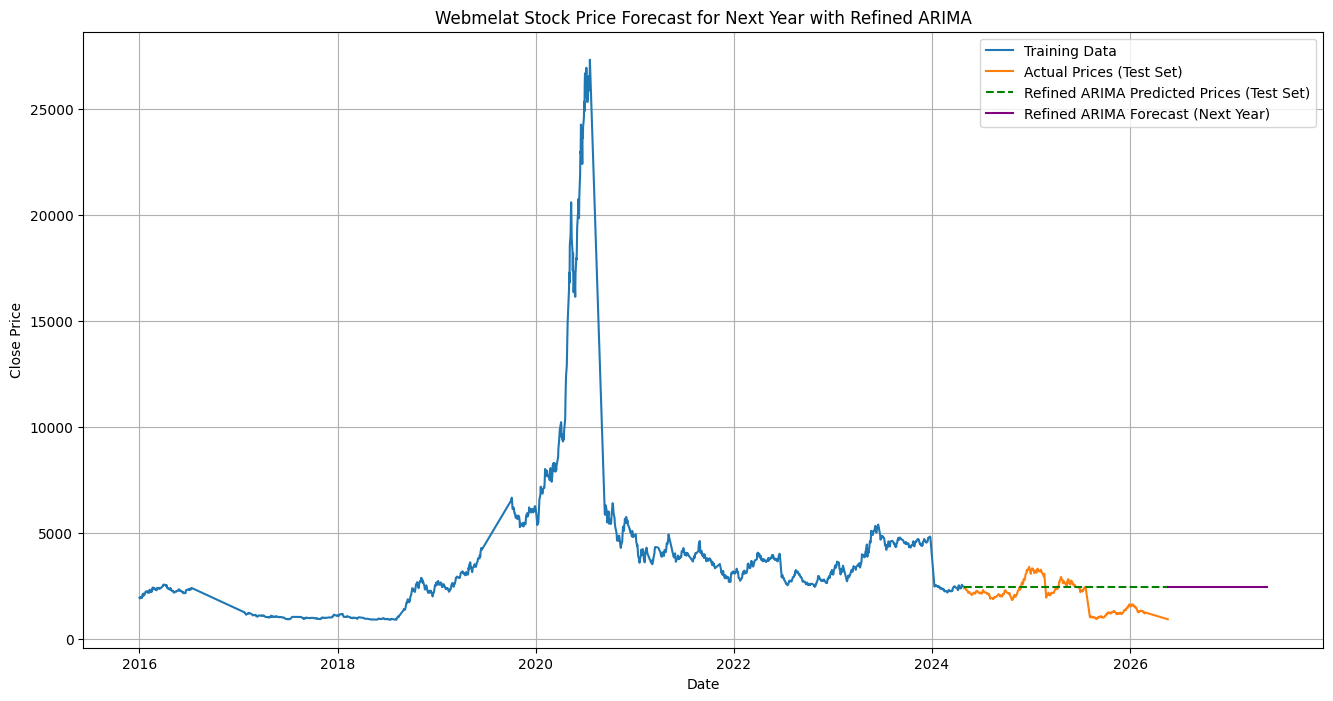

,0
2026-05-20,2456.0
2026-05-21,2456.0
2026-05-22,2456.0
2026-05-23,2456.0
2026-05-24,2456.0


In [ ]:
# Forecast future values using the refined ARIMA model (model_refined_fit)
forecast_refined = model_refined_fit.forecast(steps=n_forecast_steps)

# Create a Series for the refined forecast with the new dates
forecast_series_refined = pd.Series(forecast_refined.values, index=forecast_dates)

# Plot the historical data, test data, and the refined forecast
plt.figure(figsize=(16, 8))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Actual Prices (Test Set)')
plt.plot(test.index, predictions_refined, color='green', linestyle='--', label='Refined ARIMA Predicted Prices (Test Set)')
plt.plot(forecast_series_refined.index, forecast_series_refined, color='purple', label='Refined ARIMA Forecast (Next Year)')
plt.title('Webmelat Stock Price Forecast for Next Year with Refined ARIMA')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

display(forecast_series_refined.head())

### 13. Zoomed-in Forecast for the Next Year

This plot focuses on the refined ARIMA model's forecast for the next year, providing a clearer view of the predicted trends and values.

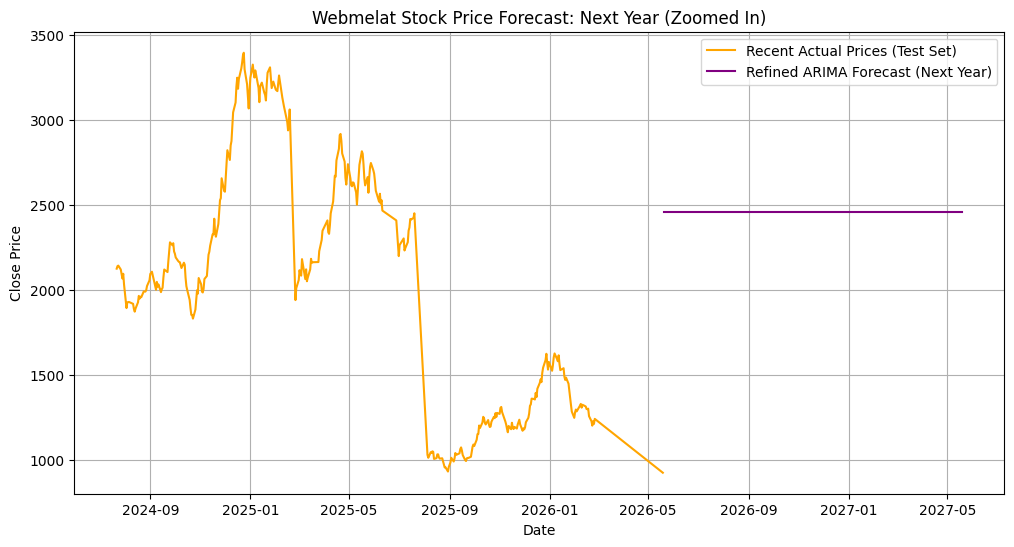

In [ ]:
plt.figure(figsize=(12, 6))
# Plot a portion of the actual test data for context
plt.plot(test.index[-n_forecast_steps:], test[-n_forecast_steps:], label='Recent Actual Prices (Test Set)', color='orange')
plt.plot(forecast_series_refined.index, forecast_series_refined, color='purple', label='Refined ARIMA Forecast (Next Year)')
plt.title('Webmelat Stock Price Forecast: Next Year (Zoomed In)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

### 14. Residual Analysis (ADF Test)

We will now perform an Augmented Dickey-Fuller (ADF) test on the residuals of the best-performing ARIMA model to check for stationarity. Ideally, the residuals should be stationary, indicating that all underlying patterns have been captured by the model.

In [ ]:
print('ADF Test Results for ARIMA Model Residuals:')
adf_test(model_fit.resid)


ADF Test Results for ARIMA Model Residuals:
ADF Statistic: -40.80
p-value: 0.00
Critical Values:
   1%: -3.43
   5%: -2.86
   10%: -2.57
Reject the null hypothesis (Ho), the series is stationary


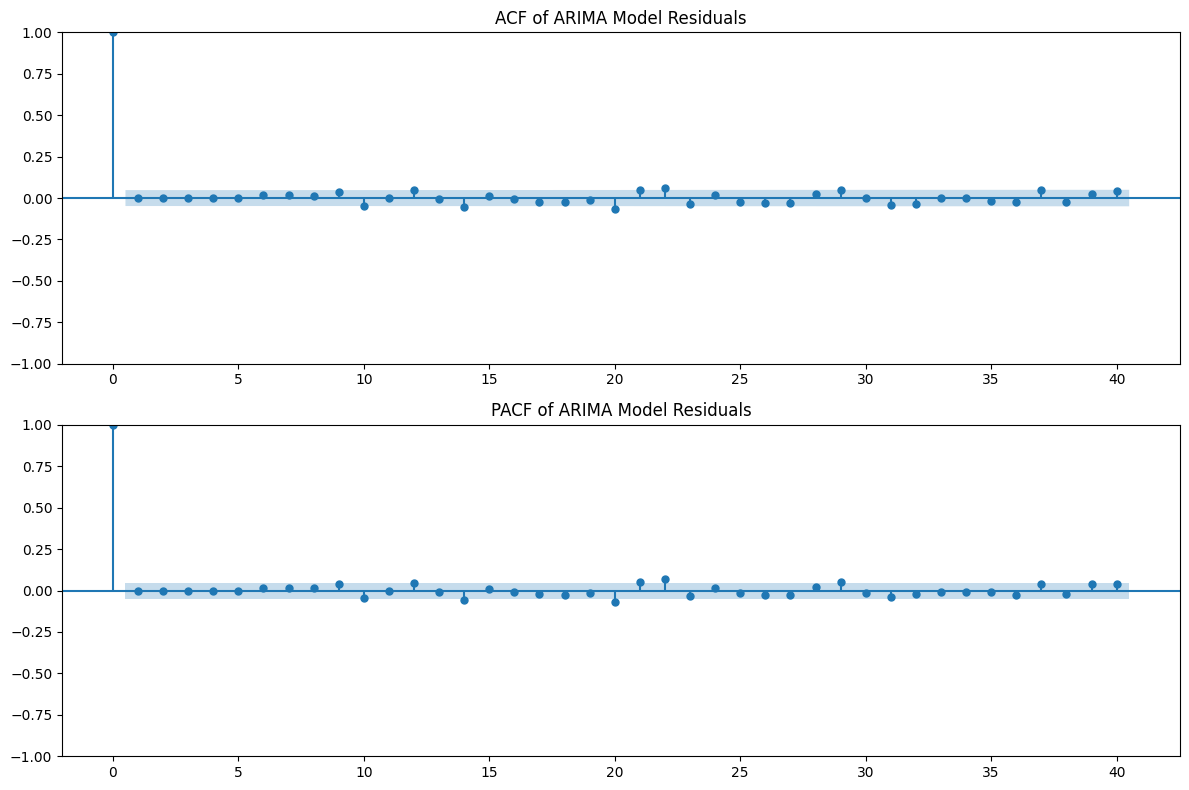

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(model_fit.resid, ax=axes[0], lags=40)
axes[0].set_title('ACF of ARIMA Model Residuals')
plot_pacf(model_fit.resid, ax=axes[1], lags=40, method='ywm')
axes[1].set_title('PACF of ARIMA Model Residuals')
plt.tight_layout()
plt.show()

## 15. Review Forecasting with Confidence Intervals

Generating forecast with confidence intervals...


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


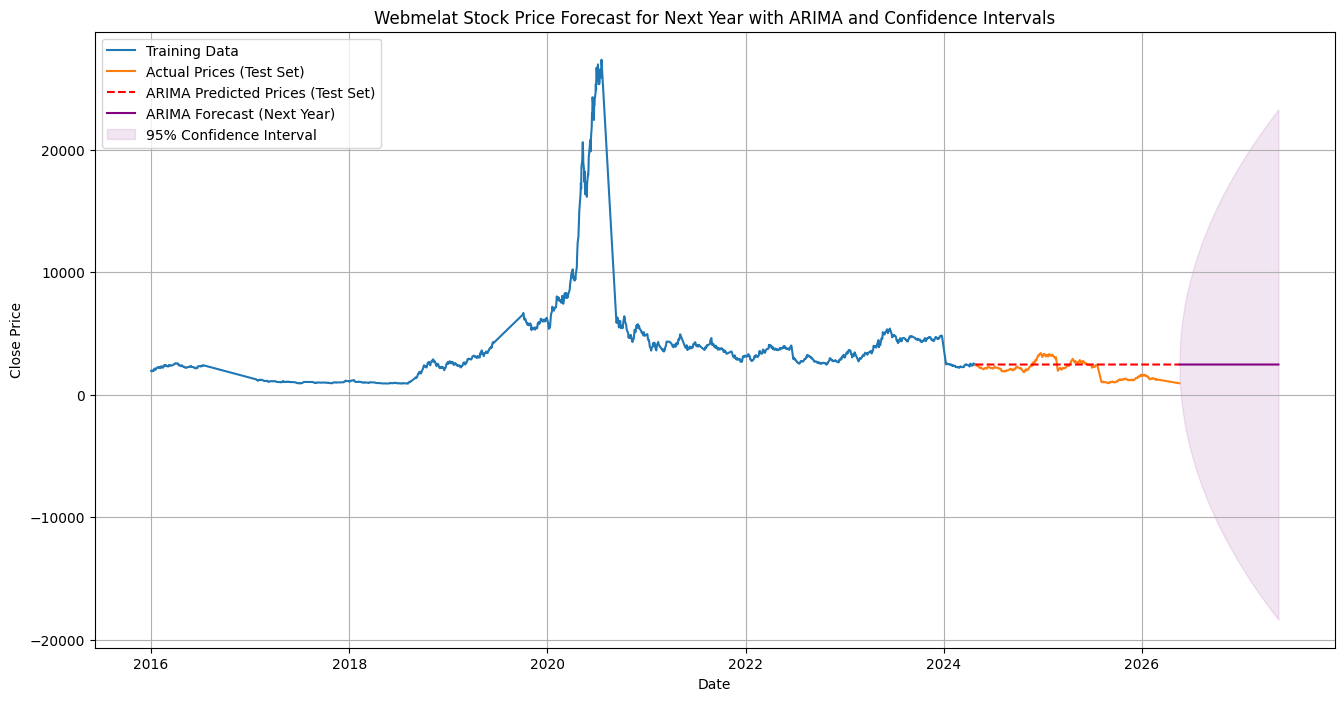


First few rows of the forecast with confidence intervals:


,Forecast,Lower CI,Upper CI
2026-05-20,2457.134764,1346.525263,3567.744264
2026-05-21,2456.530926,921.575317,3991.486534
2026-05-22,2456.373404,573.145416,4339.601392
2026-05-23,2456.531057,278.693910,4634.368203
2026-05-24,2456.821236,11.368923,4902.273549


In [ ]:
print('Generating forecast with confidence intervals...')

# Get forecast with confidence intervals
forecast_results = model_fit.get_forecast(steps=n_forecast_steps)

# Extract predicted means and confidence intervals
forecast_mean = forecast_results.predicted_mean
forecast_conf_int = forecast_results.conf_int(alpha=0.05) # 95% confidence interval

# Create a Series for the forecast mean and confidence intervals with the correct dates
forecast_mean_series = pd.Series(forecast_mean.values, index=forecast_dates)
forecast_lower_series = pd.Series(forecast_conf_int.iloc[:, 0].values, index=forecast_dates)
forecast_upper_series = pd.Series(forecast_conf_int.iloc[:, 1].values, index=forecast_dates)

# Plot the historical data, test data, and the forecast with confidence intervals
plt.figure(figsize=(16, 8))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Actual Prices (Test Set)')
plt.plot(test.index, predictions, color='red', linestyle='--', label='ARIMA Predicted Prices (Test Set)')
plt.plot(forecast_mean_series.index, forecast_mean_series, color='purple', label='ARIMA Forecast (Next Year)')
plt.fill_between(forecast_lower_series.index, forecast_lower_series, forecast_upper_series, color='purple', alpha=0.1, label='95% Confidence Interval')

plt.title('Webmelat Stock Price Forecast for Next Year with ARIMA and Confidence Intervals')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

print('\nFirst few rows of the forecast with confidence intervals:')
display(pd.DataFrame({'Forecast': forecast_mean_series, 'Lower CI': forecast_lower_series, 'Upper CI': forecast_upper_series}).head())

### 16. Log Returns ARIMA

Generating forecast with confidence intervals for Log Returns ARIMA model...


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


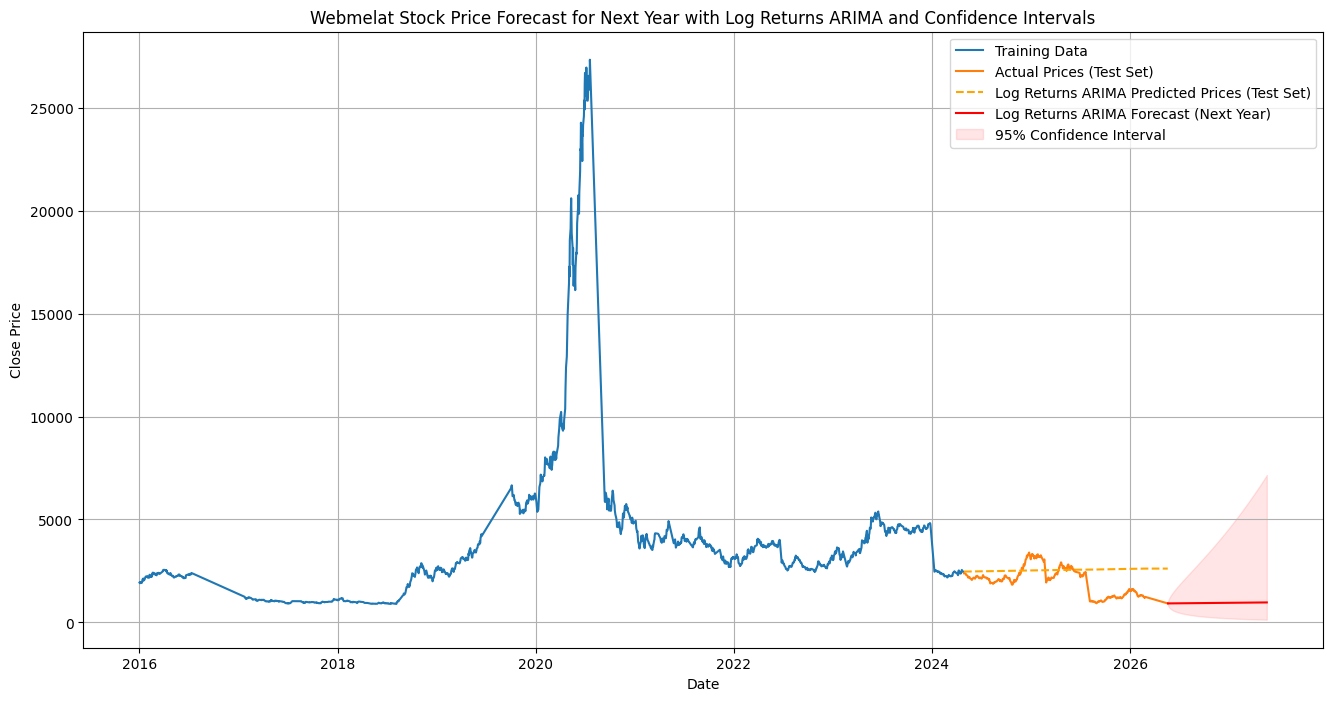


First few rows of the forecast with confidence intervals (Log Returns ARIMA):


,Forecast,Lower CI,Upper CI
2026-05-20,924.127558,832.413825,1025.946132
2026-05-21,924.255134,797.254517,1071.486627
2026-05-22,924.382728,771.310899,1107.832689
2026-05-23,924.510339,750.112665,1139.454654
2026-05-24,924.637968,731.931942,1168.080422


In [ ]:
print('Generating forecast with confidence intervals for Log Returns ARIMA model...')

# Get forecast results, including predicted means and standard errors for the log-differenced series
forecast_results_log_diff = model_log_diff_fit.get_forecast(steps=n_forecast_steps)

# Extract predicted means (these are for the log-differenced series)
forecast_mean_log_diff = forecast_results_log_diff.predicted_mean

# Inverse transform the forecast mean and confidence intervals
last_ts_log_value = ts_log.iloc[-1] # Get the very last log value from the full ts_log series

forecast_log_values = last_ts_log_value + forecast_mean_log_diff.cumsum()
forecast_log_values.index = forecast_dates

# Extract the standard deviation of the residuals (innovations) from the fitted log-differenced model
std_dev_log_diff_residuals = np.sqrt(model_log_diff_fit.resid.std()**2)

# Calculate the standard error of the log-level forecast, which grows with sqrt(k)
forecast_steps_range = pd.Series(np.arange(1, n_forecast_steps + 1), index=forecast_dates)
se_log_forecast = std_dev_log_diff_residuals * np.sqrt(forecast_steps_range)

# Calculate the confidence intervals for the log-level forecast
alpha = 0.05
z_score = stats.norm.ppf(1 - alpha / 2)

forecast_lower_log_values = forecast_log_values - z_score * se_log_forecast
forecast_upper_log_values = forecast_log_values + z_score * se_log_forecast

forecast_prices_log_model = pd.Series(np.exp(forecast_log_values.values), index=forecast_dates)
forecast_lower_prices_log_model = pd.Series(np.exp(forecast_lower_log_values.values), index=forecast_dates)
forecast_upper_prices_log_model = pd.Series(np.exp(forecast_upper_log_values.values), index=forecast_dates)

# Plot the historical data, test data, and the forecast with confidence intervals
plt.figure(figsize=(16, 8))
plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Actual Prices (Test Set)')
plt.plot(predicted_prices_log_diff.index, predicted_prices_log_diff, color='orange', linestyle='--', label='Log Returns ARIMA Predicted Prices (Test Set)')
plt.plot(forecast_prices_log_model.index, forecast_prices_log_model, color='red', label='Log Returns ARIMA Forecast (Next Year)')
plt.fill_between(forecast_lower_prices_log_model.index,
                 forecast_lower_prices_log_model,
                 forecast_upper_prices_log_model, color='red', alpha=0.1, label='95% Confidence Interval')

plt.title('Webmelat Stock Price Forecast for Next Year with Log Returns ARIMA and Confidence Intervals')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()

print('\nFirst few rows of the forecast with confidence intervals (Log Returns ARIMA):')
display(pd.DataFrame({'Forecast': forecast_prices_log_model, 'Lower CI': forecast_lower_prices_log_model, 'Upper CI': forecast_upper_prices_log_model}).head())

### 17. Zoomed-in Forecast for the Next Year (Log Returns ARIMA)

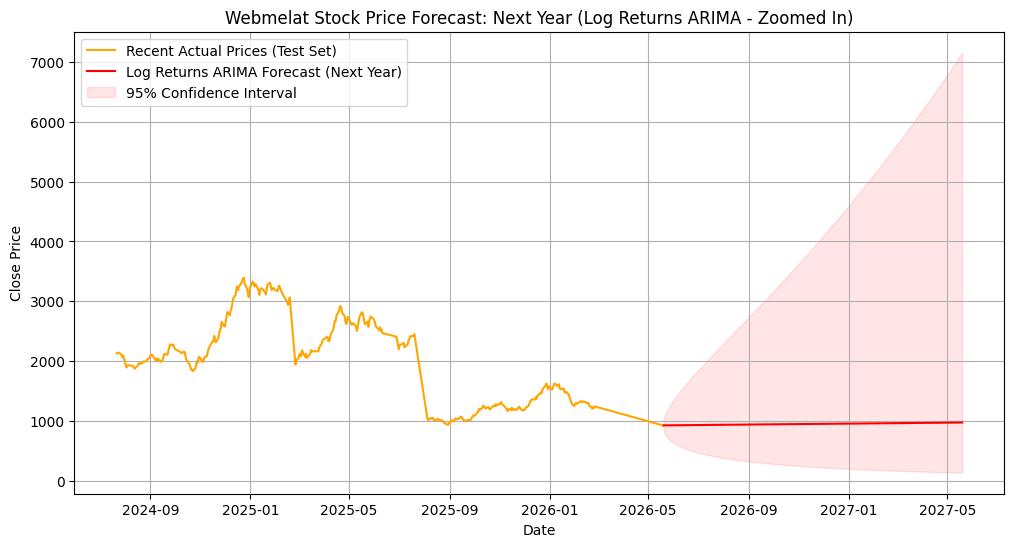

In [ ]:
plt.figure(figsize=(12, 6))
# Plot a portion of the actual test data for context
plt.plot(test.index[-n_forecast_steps:], test[-n_forecast_steps:], label='Recent Actual Prices (Test Set)', color='orange')
plt.plot(forecast_prices_log_model.index, forecast_prices_log_model, color='red', label='Log Returns ARIMA Forecast (Next Year)')
plt.fill_between(forecast_lower_prices_log_model.index,
                 forecast_lower_prices_log_model,
                 forecast_upper_prices_log_model, color='red', alpha=0.1, label='95% Confidence Interval')

plt.title('Webmelat Stock Price Forecast: Next Year (Log Returns ARIMA - Zoomed In)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.show()